In [1]:
import pandas as pd 

df=pd.read_csv("spam.csv")
df.head()

,Category,Message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [2]:
df['Category'].value_counts()

Category
ham     4825
spam     747
Name: count, dtype: int64

In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df['Message'],df['Category'],test_size=0.2,random_state=25)

In [9]:
X_train.iloc[2]

'SMS. ac Blind Date 4U!: Rodds1 is 21/m from Aberdeen, United Kingdom. Check Him out http://img. sms. ac/W/icmb3cktz8r7!-4 no Blind Dates send HIDE'

In [10]:
#This is text data and ML model do not understand text so we need to convert it to numeric value
#here we also cannot use one hot encoding 
#so here will use count vectorizer

from sklearn.feature_extraction.text import CountVectorizer

# first lets see a example how it works 
corpus = [
    'This is the first document.',
    'This document is the second document.',
    'And this is the third one.',
    'Is this the first document?',
]
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(corpus)

In [11]:
vectorizer.get_feature_names_out()


array(['and', 'document', 'first', 'is', 'one', 'second', 'the', 'third',
       'this'], dtype=object)

In [13]:
X.toarray()

array([[0, 1, 1, 1, 0, 0, 1, 0, 1],
       [0, 2, 0, 1, 0, 1, 1, 0, 1],
       [1, 0, 0, 1, 1, 0, 1, 1, 1],
       [0, 1, 1, 1, 0, 0, 1, 0, 1]])

In [23]:
#okay now lets apply it to our spam classificaation problem 

v=CountVectorizer()
X_train_count=v.fit_transform(X_train)
X_test_count=v.transform(X_test)
X_train_count.toarray()

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(4457, 7767))

In [18]:
v.get_feature_names_out()

array(['00', '000', '008704050406', ..., 'zyada', 'èn', '〨ud'],
      shape=(7767,), dtype=object)

In [21]:
len(X_train_count.toarray()[2])

7767

In [22]:
from sklearn.naive_bayes import MultinomialNB, GaussianNB

model=MultinomialNB()
model.fit(X_train_count,y_train)


,alpha,1.0
,force_alpha,True
,fit_prior,True
,class_prior,None


In [24]:
y_pred=model.predict(X_test_count)

In [27]:
from sklearn.metrics import classification_report, confusion_matrix

report=classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       958
        spam       0.97      0.92      0.95       157

    accuracy                           0.99      1115
   macro avg       0.98      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115



<Axes: >

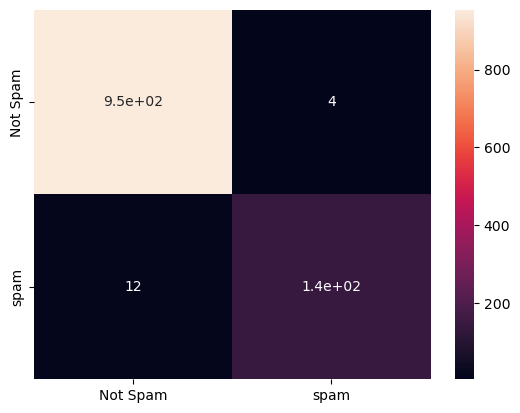

In [30]:
cm=confusion_matrix(y_test,y_pred)

classes=['Not Spam','spam']

import seaborn as sns 
sns.heatmap(cm,annot=True, xticklabels=classes,yticklabels=classes)

In [31]:
from sklearn.pipeline import Pipeline
pipe= Pipeline([
    ('vectorize', CountVectorizer()),
    ('nb',MultinomialNB())
])

pipe.fit(X_train,y_train)

y_pred=pipe.predict(X_test)
report=classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       958
        spam       0.97      0.92      0.95       157

    accuracy                           0.99      1115
   macro avg       0.98      0.96      0.97      1115
weighted avg       0.99      0.99      0.99      1115

